# A Simple Regression Model

This tutorial walks you through writing and running your first Hybrid Pluck models,
starting from a simple linear regression model and building up to regression models
that mix discrete and continuous choices: outliers, a choice between one line and
two, and a polynomial of unknown degree.

Each model is a short Hybrid Pluck program. Hybrid Pluck returns a symbolic
representation of the *exact* Bayesian posterior, which this notebook then plots.

[LANGUAGE.md](LANGUAGE.md) describes the whole language, which is functional with
a lisp-style syntax. The main probabilistic primitives and queries used in this 
tutorial are as follows:

- `(normal mu sd)` draws a Gaussian and `(flip p)` a biased coin.
- `(real=? e y)` observes that the Gaussian expression `e` equals the number `y`.
- `(Posterior value evidence)` asks for the distribution of `value` given that
  `evidence` is true.

**Running the notebook.** This notebook runs locally, *outside* the Docker container
used for artifact evaluation. You need a Python installation with NumPy, SciPy,
Matplotlib and Jupyter; we recommend `uv`, which installs them in one step. From the
repository root:

```sh
uv run --with numpy,scipy,matplotlib,notebook jupyter notebook docs/TUTORIAL.ipynb
```

The Hybrid Pluck programs themselves run in the Docker image. Make sure that the image
`hybrid-pluck:popl` is loaded and runs correctly (see the README): the notebook calls
`docker run` for every program. If you built the engine from source instead, set the
environment variable `PLUCK` to the binary's absolute path before starting Jupyter, and
the notebook calls it directly. Every model in this tutorial runs in well under a
second.

The next cell has the glue: a function that runs a program and returns Pluck's
answer, parsed from its `--json` output, and a few helpers that turn a posterior
into something we can plot.

In [1]:
import json, os, re, subprocess, tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

IMAGE = "hybrid-pluck:popl"
PLUCK = os.environ.get("PLUCK")        # a local pluck binary; if unset, use the image


def pluck_output(program, json_output=False):
    """Run a Hybrid Pluck program and return what the `pluck` command prints.

    By default the program is piped into a fresh container, which runs `pluck` on
    it. With PLUCK set, it is written to a file and the local binary runs it."""
    flags = ["--json"] if json_output else []
    if PLUCK:
        with tempfile.NamedTemporaryFile("w", suffix=".pluck", delete=False) as f:
            f.write(program)
        result = subprocess.run([PLUCK, f.name] + flags, capture_output=True, text=True)
        os.unlink(f.name)
    else:
        script = "cat > /tmp/model.pluck && pluck /tmp/model.pluck " + " ".join(flags)
        result = subprocess.run(["docker", "run", "--rm", "-i", "--network", "none", IMAGE, "bash", "-c", script],
                                input=program, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
    return result.stdout


def run_pluck(program):
    """Run a program and return {query name: list of posterior components}.

    A component is one possible value of the query, with its probability and the
    posteriors of the continuous variables it contains. Each Gaussian block is a
    (variable names, mean vector, covariance matrix) triple."""
    answers = {}
    for query in json.loads(pluck_output(program, json_output=True)):
        components = []
        for item in query["kind"]["items"]:
            post = item["posteriors"]
            components.append({
                "value": item["display"],
                "prob": np.exp(item["log_probability"]),
                "gaussians": [(g["var_order"], np.array(g["mean"][0]),
                               np.array(g["cov"][0]).reshape(len(g["var_order"]), -1))
                              for g in post["gaussian"]],
                "betas": [(b["Beta"]["name"], b["Beta"]["a"], b["Beta"]["b"]) for b in post["beta"]],
            })
        answers[query["query"]] = components
    return answers


def num(v, precision=12):
    """A float as a Pluck literal. Pluck reads 0.000001 but not 1e-6."""
    return np.format_float_positional(float(v), precision=precision, trim="0")


def pluck_list(values, precision=4):
    return "[" + ", ".join(num(v, precision) for v in values) + "]"


# --- Summaries of a posterior ---------------------------------------------------

def marginal(components, key=lambda value: value):
    """Total probability of each distinct value (or of key(value))."""
    totals = {}
    for c in components:
        k = key(c["value"])
        totals[k] = totals.get(k, 0.0) + c["prob"]
    return totals


def gaussian(component, names):
    """Posterior mean and covariance of the named Gaussian variables, in that order."""
    for order, mean, cov in component["gaussians"]:
        if all(n in order for n in names):
            idx = [order.index(n) for n in names]
            return mean[idx], cov[np.ix_(idx, idx)]
    raise KeyError(names)


def density(components, name, grid):
    """Posterior density of one Gaussian variable: a mixture over the components."""
    pdf = np.zeros_like(grid)
    for c in components:
        (m,), ((v,),) = gaussian(c, [name])
        pdf += c["prob"] * np.exp(-0.5 * (grid - m) ** 2 / v) / np.sqrt(2 * np.pi * v)
    return pdf


def curve_band(components, grid, block=0):
    """Posterior mean and standard deviation, at each x in grid, of the curve
    c0 + c1 x + c2 x^2 + ... whose coefficients are the Gaussian variables of one
    block of each component (for a line: the intercept and the slope)."""
    mean, second = np.zeros_like(grid), np.zeros_like(grid)
    for c in components:
        names, m, S = c["gaussians"][block]
        Phi = np.vander(grid, len(names), increasing=True)
        mu, var = Phi @ m, np.einsum("ij,jk,ik->i", Phi, S, Phi)
        mean += c["prob"] * mu
        second += c["prob"] * (var + mu ** 2)
    return mean, np.sqrt(np.maximum(second - mean ** 2, 0.0))


def indicators(component):
    """The booleans in a component's value, as a vector of 0s and 1s."""
    return np.array([t == "True" for t in re.findall(r"True|False", component["value"])], float)


# --- Plotting ----------------------------------------------------------------------

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#52514e", "#b5b4ae"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]   # light to dark
REDS = LinearSegmentedColormap.from_list("reds", ["#f6c6b6", "#e34948", "#7a1b1b"])
ORANGE_BLUE = LinearSegmentedColormap.from_list("orange_blue", [ORANGE, "#8e8d88", BLUE])
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (6.4, 3.4), "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "legend.frameon": False,
})


def plot_points(ax, xs, ys, label="data", **kw):
    ax.scatter(xs, ys, s=28, color=INK, zorder=3, label=label, **kw)


def plot_colored_points(ax, xs, ys, probabilities, cmap):
    """Points colored by a probability; returns the mappable for a colorbar."""
    return ax.scatter(xs, ys, c=probabilities, cmap=cmap, vmin=0, vmax=1, s=40, zorder=3,
                      edgecolors=INK, linewidths=0.5)


def plot_band(ax, grid, mean, sd, color=BLUE, label=None):
    """A posterior mean curve with a band of two standard deviations."""
    ax.plot(grid, mean, color=color, lw=1.8, label=label)
    ax.fill_between(grid, mean - 2 * sd, mean + 2 * sd, color=color, alpha=0.15, lw=0)


# A first run, to check that everything is in place.
print(pluck_output("(query coin (Marginal (flip 0.5)))"))

coin:
  False  0.5
  True  0.5




We will use the following example data: ten points on the line $y = 2 + 0.5x$, sampled
with Gaussian noise of standard deviation 0.5.

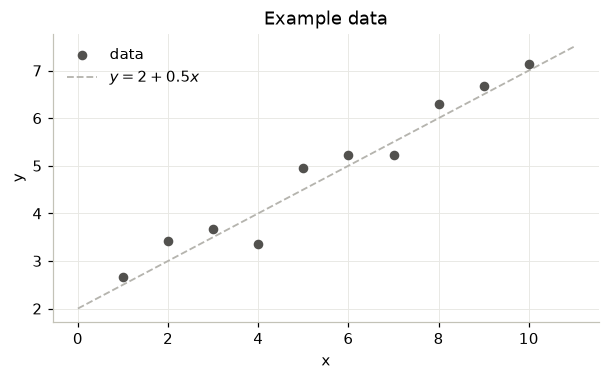

In [2]:
rng = np.random.default_rng(1)
TRUE_A, TRUE_B, SIGMA = 2.0, 0.5, 0.5
xs = np.arange(1.0, 11.0)
ys = TRUE_A + TRUE_B * xs + rng.normal(0, SIGMA, size=xs.size)
grid = np.linspace(0, 11, 100)

fig, ax = plt.subplots()
plot_points(ax, xs, ys)
ax.plot(grid, TRUE_A + TRUE_B * grid, "--", color=MUTED, lw=1.2, label="$y = 2 + 0.5x$")
ax.set(xlabel="x", ylabel="y", title="Example data")
ax.legend();

## Linear Regression

We start with a simple linear regression model, where we assume every point is a noisy
reading of a line, $y_i = a + b\,x_i + \varepsilon_i$ with
$\varepsilon_i \sim N(0, \sigma^2)$. Throughout this tutorial we will be doing **Bayesian**
regression: each parameter has a *prior*, which represents our uncertainty about its
value before we see the data. Given the data, Hybrid Pluck returns the *posterior*, our
updated belief about the parameters. Here the parameters are the intercept $a$ and the
slope $b$, with zero-centered Gaussian priors for both.

The full Hybrid Pluck model is the program below. A `line` is a data type with two
fields, and `predict` evaluates it at a point. `observe` builds the evidence: for each
$x_i$ it draws a fresh Gaussian reading `(normal (predict l x) sigma)` and `real=?`
observes it at $y_i$; `list=?` does this for every pair. The query draws a line from
the prior and returns its posterior given the evidence.

A small Python wrapper pastes the data and the prior standard deviations into the
program as literals, so that both are easy to change from the notebook.

In [3]:
def regression_program(xs, ys, sigma=SIGMA, a_sd=10.0, b_sd=10.0):
    return f"""
(define xs {pluck_list(xs)})
(define ys {pluck_list(ys)})

;; A line y = a + b*x.
(define-type line (Line a b))
(define (predict l x) (match l Line a b => (+. a (*. b x))))

;; The evidence: every y_i is a noisy reading of the line at x_i.
(define (observe l xs ys)
  (list=? real=? (map (fn x -> (normal (predict l x) {num(sigma)})) xs) ys))

(query line
  (let ((l (Line (normal 0.0 {num(a_sd)}) (normal 0.0 {num(b_sd)}))))
    (Posterior l (observe l xs ys))))
"""

print(pluck_output(regression_program(xs, ys)))

line:
  (Line a b)  1
        a, b ~ Joint Gaussian:
          mean = [2.1195, 0.4986]
          cov  = [0.1165, -0.0166]
                 [-0.0166, 0.0030]





Pluck prints each query's name, then one row per distinct value with its probability,
and under it the posterior of the continuous variables in that value. The value here
is always `(Line a b)`, so there is one row with probability 1, and `a` and `b` have a
joint Gaussian posterior. Its covariance is negative: all the data are at positive
$x$, so a larger intercept must go with a smaller slope. The posterior means are close
to the true values, 2 and 0.5.

`run_pluck` returns the same answer parsed from Pluck's `--json` output. From the joint
Gaussian we can draw the posterior over lines as a band, and the posterior of the
slope as a density.

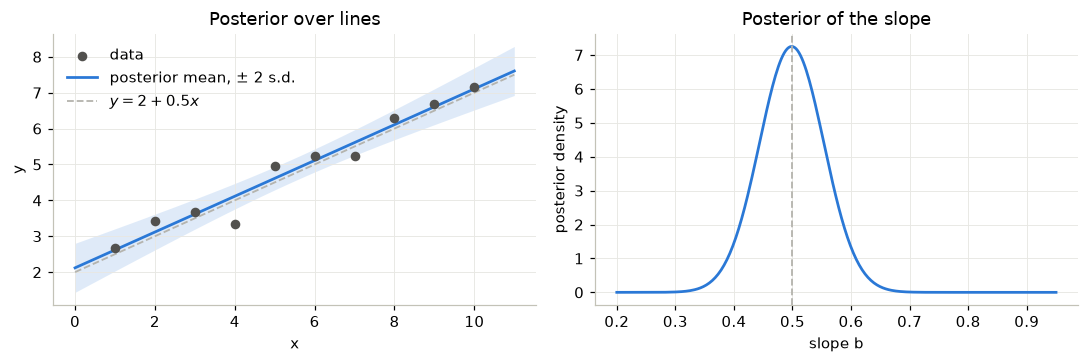

In [4]:
post = run_pluck(regression_program(xs, ys))["line"]
mean, sd = curve_band(post, grid)
b_grid = np.linspace(0.2, 0.95, 300)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
plot_points(ax1, xs, ys)
plot_band(ax1, grid, mean, sd, label=r"posterior mean, $\pm$ 2 s.d.")
ax1.plot(grid, TRUE_A + TRUE_B * grid, "--", color=MUTED, lw=1.2, label="$y = 2 + 0.5x$")
ax1.set(xlabel="x", ylabel="y", title="Posterior over lines")
ax1.legend()
ax2.plot(b_grid, density(post, "b", b_grid), color=BLUE, lw=1.8)
ax2.axvline(TRUE_B, ls="--", color=MUTED, lw=1.2)
ax2.set(xlabel="slope b", ylabel="posterior density", title="Posterior of the slope")
fig.tight_layout()

> **How does the prior on the intercept change the posterior for the slope?**

The intercept's prior is `(normal 0.0 a_sd)`. Let's see what happens as we go from a
very narrow prior, `(normal 0.0 0.01)`, to a wide one, `(normal 0.0 10.0)`. We only
have ten data points, and `(normal 0.0 0.01)` is a *very* strong belief that the
intercept is 0. So we should expect the narrow priors to hold the line close to the
origin, and the wide ones to let the intercept move and capture the data.

intercept prior sd  0.01:  a =  0.00 +- 0.01   b = 0.801 +- 0.026


intercept prior sd   0.1:  a =  0.17 +- 0.10   b = 0.777 +- 0.029


intercept prior sd   0.3:  a =  0.92 +- 0.23   b = 0.669 +- 0.041


intercept prior sd   1.0:  a =  1.90 +- 0.32   b = 0.530 +- 0.053


intercept prior sd   3.0:  a =  2.09 +- 0.34   b = 0.502 +- 0.055


intercept prior sd  10.0:  a =  2.12 +- 0.34   b = 0.499 +- 0.055


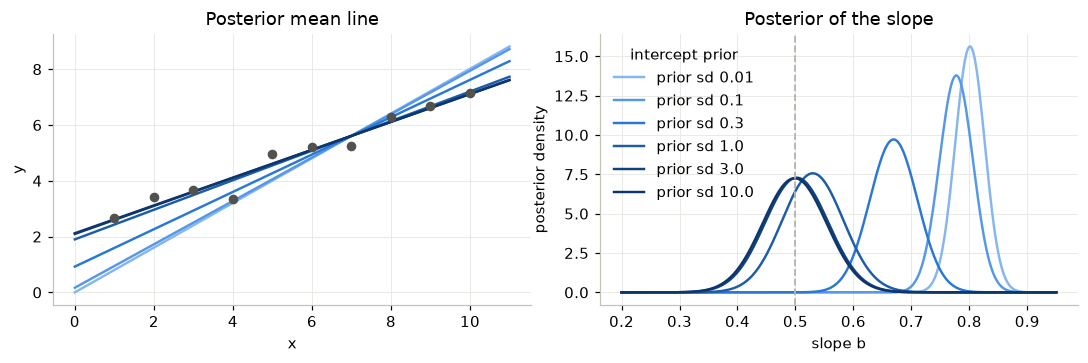

In [5]:
a_sds = [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
plot_points(ax1, xs, ys)
for a_sd, color in zip(a_sds, RAMP):
    post = run_pluck(regression_program(xs, ys, a_sd=a_sd))["line"]
    (ma, mb), cov = gaussian(post[0], ["a", "b"])
    print(f"intercept prior sd {a_sd:>5}:  a = {ma:5.2f} +- {np.sqrt(cov[0, 0]):.2f}"
          f"   b = {mb:.3f} +- {np.sqrt(cov[1, 1]):.3f}")
    ax1.plot(grid, curve_band(post, grid)[0], color=color, lw=1.6, label=f"prior sd {a_sd}")
    ax2.plot(b_grid, density(post, "b", b_grid), color=color, lw=1.6, label=f"prior sd {a_sd}")
ax1.set(xlabel="x", ylabel="y", title="Posterior mean line")
ax2.axvline(TRUE_B, ls="--", color=MUTED, lw=1.2)
ax2.set(xlabel="slope b", ylabel="posterior density", title="Posterior of the slope")
ax2.legend(title="intercept prior")
fig.tight_layout()

A narrow prior pins the intercept near 0, which directly affects the slope: with the
left end of the line held down at the origin, the right end has to rise to keep the
line through the data, so the slope gets steeper. Once the prior is of a comparable
scale to the data, the data dominate and the prior stops mattering: the prior sds of 3
and 10 give essentially the same answer.

Try centering the data by subtracting the mean of `xs`. The posterior covariance
between $a$ and $b$ is then zero, and you should see that the prior on the intercept
no longer affects the slope at all.

## Handling Outliers

Real data often have points that do not follow the overall trend. Let's turn two of our
points into outliers, one far from the line and one less so, and see what the model
does.

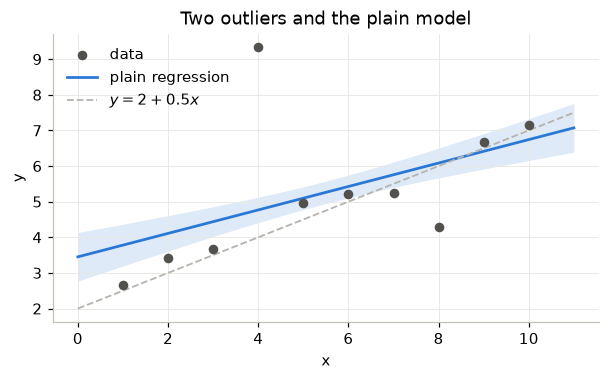

In [6]:
ys_out = ys.copy()
ys_out[3] += 6.0
ys_out[7] -= 2.0

post = run_pluck(regression_program(xs, ys_out))["line"]
mean, sd = curve_band(post, grid)

fig, ax = plt.subplots()
plot_points(ax, xs, ys_out)
plot_band(ax, grid, mean, sd, label="plain regression")
ax.plot(grid, TRUE_A + TRUE_B * grid, "--", color=MUTED, lw=1.2, label="$y = 2 + 0.5x$")
ax.set(xlabel="x", ylabel="y", title="Two outliers and the plain model")
ax.legend();

The line is dragged toward the outliers, but the posterior stays narrow. We are
confidently wrong, because the model is a poor description of the process that
generated the data.

We can make the model *robust* to outliers by giving each point an indicator of
whether it is an outlier. This is a *latent* variable: we never observe whether it is
true or false, so Hybrid Pluck must sum over all $2^{10}$ possible outlier assignments,
weighted by how well each one explains the data, to get the posterior. Each assignment
on its own is an ordinary Bayesian linear regression problem.

In the program, the indicator is a `flip`. We walk through the data recursively, and
at each step flip a coin with probability `p-out` to decide whether the point is an
outlier, in which case it is read with a much wider noise level (standard deviation 10
instead of 0.5). The query returns both the indicators and the line, so we get a
posterior over both.

Note that we observe each point *inside* the step that draws its indicator, rather
than drawing all the indicators up front. This keeps the decision diagram small
(LANGUAGE.md, Section 6).

In [7]:
def outlier_program(xs, ys, p_out=0.1, sigma=SIGMA, sigma_out=10.0):
    return f"""
(define xs {pluck_list(xs)})
(define ys {pluck_list(ys)})

(define-type line (Line a b))
(define (predict l x) (match l Line a b => (+. a (*. b x))))

;; Each point is an outlier with probability p-out. Observe it with the matching
;; noise level, and return the outlier indicators together with the evidence.
(define (observe l xs ys)
  (match xs
    Nil => (Pair Nil true)
    Cons x xs =>
      (match ys
        Cons y ys =>
          (let ((out  (flip {num(p_out)}))
                (sd   (if out {num(sigma_out)} {num(sigma)}))
                (ok   (real=? (normal (predict l x) sd) y))
                (rest (observe l xs ys)))
            (Pair (Cons out (fst rest)) (and ok (snd rest)))))))

(query outliers
  (let ((l (Line (normal 0.0 10.0) (normal 0.0 10.0)))
        (r (observe l xs ys)))
    (Posterior (Pair (fst r) l) (snd r))))
"""

post = run_pluck(outlier_program(xs, ys_out))["outliers"]
print(f"{len(post)} components. The most probable:")
for c in sorted(post, key=lambda c: -c["prob"])[:3]:
    print(f"  {c['prob']:.3f}  {c['value']}")

1024 components. The most probable:
  0.570  ([False, False, False, True, False, False, False, True, False, False], (Line a b))
  0.370  ([False, False, False, True, False, False, False, False, False, False], (Line a b))
  0.005  ([False, False, False, True, False, False, False, False, False, True], (Line a b))


Each component is one combination of indicators, with its own line. Summing over them gives
the three things we want: the probability that each point is an outlier, the posterior
over the number of outliers, and the posterior over lines.

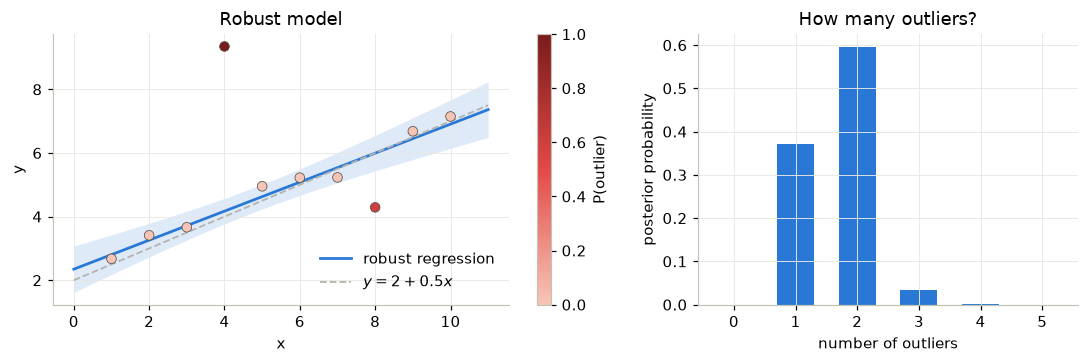

In [8]:
def outlier_summary(post):
    p_point = sum(c["prob"] * indicators(c) for c in post)
    p_count = marginal(post, key=lambda v: v.count("True"))
    return p_point, p_count

p_point, p_count = outlier_summary(post)
mean, sd = curve_band(post, grid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [3, 2]})
sc = plot_colored_points(ax1, xs, ys_out, p_point, REDS)
plot_band(ax1, grid, mean, sd, label="robust regression")
ax1.plot(grid, TRUE_A + TRUE_B * grid, "--", color=MUTED, lw=1.2, label="$y = 2 + 0.5x$")
fig.colorbar(sc, ax=ax1, label="P(outlier)")
ax1.set(xlabel="x", ylabel="y", title="Robust model")
ax1.legend()
counts = range(0, 6)
ax2.bar(counts, [p_count.get(n, 0.0) for n in counts], color=BLUE, width=0.6)
ax2.set(xlabel="number of outliers", ylabel="posterior probability", title="How many outliers?")
fig.tight_layout()

The far outlier has probability close to 1 of being an outlier, and the ordinary points
close to 0. The milder one is genuinely ambiguous: at `p-out = 0.1` it is an outlier
with probability about 0.6, so the count posterior is split between 1 and 2. The
line's posterior is back near the truth, now that it no longer has to fit the
outliers.

> **When you change the prior probability of outliers, how does this change the
> posterior on the number of outliers?**

p-out = 0.01  P(outlier) per point: [0.   0.   0.   1.   0.   0.   0.   0.12 0.   0.  ]


p-out = 0.05  P(outlier) per point: [0.   0.   0.   1.   0.   0.   0.   0.42 0.   0.01]


p-out = 0.1   P(outlier) per point: [0.01 0.01 0.01 1.   0.01 0.01 0.01 0.6  0.01 0.01]


p-out = 0.3   P(outlier) per point: [0.03 0.03 0.02 1.   0.03 0.02 0.03 0.85 0.03 0.03]


p-out = 0.5   P(outlier) per point: [0.06 0.06 0.05 1.   0.06 0.05 0.07 0.92 0.06 0.07]


p-out = 0.8   P(outlier) per point: [0.23 0.21 0.2  1.   0.21 0.19 0.25 0.96 0.23 0.24]


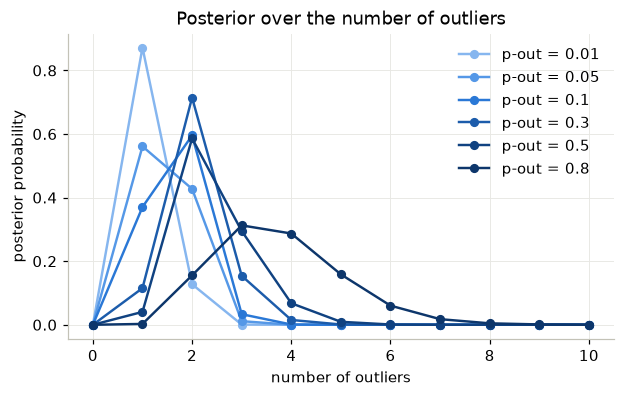

In [9]:
p_outs = [0.01, 0.05, 0.1, 0.3, 0.5, 0.8]
counts = np.arange(0, 11)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for p_out, color in zip(p_outs, RAMP):
    post = run_pluck(outlier_program(xs, ys_out, p_out=p_out))["outliers"]
    p_point, p_count = outlier_summary(post)
    ax.plot(counts, [p_count.get(n, 0.0) for n in counts], "o-", color=color, lw=1.6, ms=5,
            label=f"p-out = {p_out}")
    print(f"p-out = {p_out:<5} P(outlier) per point: {np.round(p_point, 2)}")
ax.set(xlabel="number of outliers", ylabel="posterior probability",
       title="Posterior over the number of outliers")
ax.legend();

The far outlier is found whatever the prior: its indicator stays near 1 even at
`p-out = 0.01`, because a point that far out is extremely unlikely to come from
Gaussian noise with standard deviation 0.5. The milder outlier is where the prior
comes in. With `p-out = 0.01`, the prior is strongly against outliers, so the posterior
keeps it as an ordinary point, and the count is concentrated on 1. By `p-out = 0.1` it
has tipped the other way, and the count's mode is 2. As `p-out` grows further, the
ordinary points get flagged more and more often, and the count spreads out to the
right.

Something to try: instead of fixing `p-out`, draw it once from a Beta prior,
`(p (beta 1.0 9.0))`, pass it to `observe`, and use `(flip p)` for the indicators.
The posterior then also reports a Beta distribution for the outlier rate in every
component, updated by the number of indicators it set. `examples/outliers_n08.pluck`
is this model.

## One or two lines?

Now suppose we have a data set that might be a mixture of two different processes,
here two noisy linear relationships, or might come from a single line. With a limited
amount of data it can be ambiguous which is the case, especially when most of the
points are near where the two lines cross.

To decide, we build a model that contains *both* hypotheses. A `flip` chooses between
a one-line model and a two-line model, and the posterior probability of that `flip`
tells us which model the data prefer.

Let's generate new data from two lines that cross. Notice that, visually, it is not
obvious whether there is one line or two: a single line with noisier data would also
be a reasonable fit.

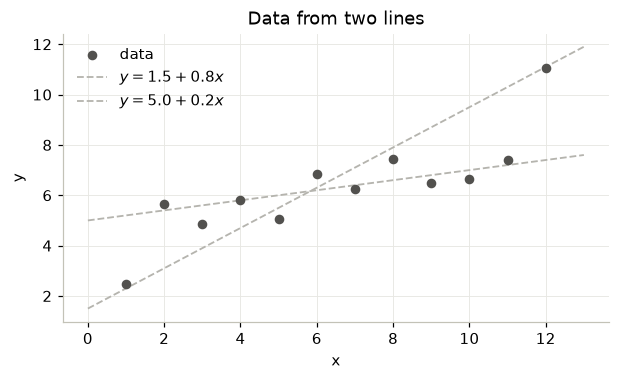

In [10]:
rng = np.random.default_rng(4)
xs2 = np.arange(1.0, 13.0)
LINE_1, LINE_2 = (1.5, 0.8), (5.0, 0.2)           # (intercept, slope)
on_line_1 = rng.random(xs2.size) < 0.5
on_line_1[0] = True
ys2 = np.where(on_line_1, LINE_1[0] + LINE_1[1] * xs2, LINE_2[0] + LINE_2[1] * xs2)
ys2 = ys2 + rng.normal(0, SIGMA, size=xs2.size)
grid2 = np.linspace(0, 13, 100)

fig, ax = plt.subplots()
plot_points(ax, xs2, ys2)
for a, b in [LINE_1, LINE_2]:
    ax.plot(grid2, a + b * grid2, "--", color=MUTED, lw=1.2, label=f"$y = {a} + {b}x$")
ax.set(xlabel="x", ylabel="y", title="Data from two lines")
ax.legend();

The program has both models. `observe-one` is the plain regression. `observe-two`
walks the points, flips a fair coin for each to decide which line it belongs to, and
observes it under that line. The first point is always assigned to line 1; otherwise
the two lines could be swapped and every posterior would come in two mirror-image
copies. The `which-model` query flips a coin with probability `p-two` to pick the
model, and returns the model's name. A second query runs the two-line model on its
own, to see the assignments and the lines.

In [11]:
def two_lines_program(xs, ys, sigma=SIGMA, p_two=0.5):
    return f"""
(define xs {pluck_list(xs)})
(define ys {pluck_list(ys)})
(define sigma {num(sigma)})

(define-type line (Line a b))
(define (predict l x) (match l Line a b => (+. a (*. b x))))
(define (icept l) (match l Line a b => a))
(define (slope l) (match l Line a b => b))
(define (fresh-line) (Line (normal 0.0 10.0) (normal 0.0 10.0)))

;; Model 1: one line explains every point.
(define (observe-one l xs ys)
  (list=? real=? (map (fn x -> (normal (predict l x) sigma)) xs) ys))

;; Model 2: each point belongs to one of two lines, chosen by a fair coin.
;; The first point always belongs to line 1. Returns the assignments and the evidence.
(define (observe-two l1 l2 first xs ys)
  (match xs
    Nil => (Pair Nil true)
    Cons x xs =>
      (match ys
        Cons y ys =>
          (let ((z    (if first true (flip 0.5)))
                (ok   (real=? (normal (predict (if z l1 l2) x) sigma) y))
                (rest (observe-two l1 l2 false xs ys)))
            (Pair (Cons z (fst rest)) (and ok (snd rest)))))))

;; Which model? A coin with probability p-two picks the two-line model.
(query which-model
  (let ((two (flip {num(p_two)}))
        (ev  (if two
                 (snd (observe-two (fresh-line) (fresh-line) true xs ys))
                 (observe-one (fresh-line) xs ys))))
    (Posterior (if two "two lines" "one line") ev)))

;; The two-line model on its own: which points go with which line, and the two lines.
(define-type lines (Lines a1 b1 a2 b2))
(query two-lines
  (let ((l1 (fresh-line))
        (l2 (fresh-line))
        (r  (observe-two l1 l2 true xs ys)))
    (Posterior (Pair (fst r) (Lines (icept l1) (slope l1) (icept l2) (slope l2)))
               (snd r))))
"""

def model_posterior(answer):
    """{model name: probability}; Pluck prints strings with their quotes."""
    return marginal(answer["which-model"], key=lambda v: v.strip('"'))

def p_two_lines(xs, ys, **settings):
    return model_posterior(run_pluck(two_lines_program(xs, ys, **settings)))["two lines"]

answer = run_pluck(two_lines_program(xs2, ys2))
p_model = model_posterior(answer)
for model, p in p_model.items():
    print(f"P({model} | data) = {p:.6f}")

P(two lines | data) = 0.999985
P(one line | data) = 0.000015


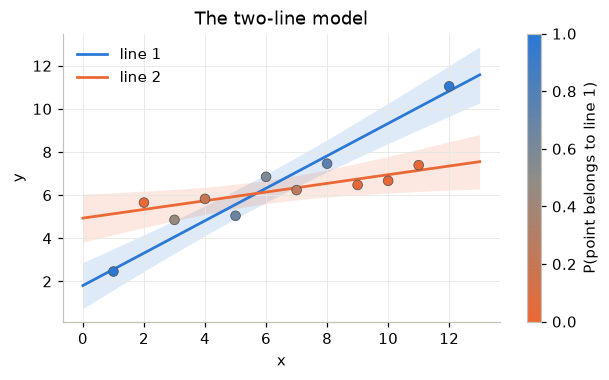

In [12]:
post2 = answer["two-lines"]
p_line_1 = sum(c["prob"] * indicators(c) for c in post2)

fig, ax = plt.subplots()
sc = plot_colored_points(ax, xs2, ys2, p_line_1, ORANGE_BLUE)
for block, color, label in [(0, BLUE, "line 1"), (1, ORANGE, "line 2")]:
    plot_band(ax, grid2, *curve_band(post2, grid2, block=block), color=color, label=label)
fig.colorbar(sc, ax=ax, label="P(point belongs to line 1)")
ax.set(xlabel="x", ylabel="y", title="The two-line model")
ax.legend();

At the noise level the data were generated with, the posterior is decisive: two lines,
with probability above 0.9999. The points near the crossing are the ambiguous ones.
Their colors are in between, and both lines' bands widen there.

> **If you greatly increase the noise level, how does this impact the posterior? Why is
> this?**

`sigma` is the noise level the model assumes (the data are not regenerated). Let's
sweep it from a quarter of the true level to far above it.

sigma =  0.25   P(two lines | data) = 1.000000
sigma =   0.5   P(two lines | data) = 0.999985
sigma =   1.0   P(two lines | data) = 0.021148
sigma =   2.0   P(two lines | data) = 0.008673
sigma =   4.0   P(two lines | data) = 0.020357
sigma =   8.0   P(two lines | data) = 0.054086
sigma =  16.0   P(two lines | data) = 0.118029
sigma =  32.0   P(two lines | data) = 0.211497
sigma =  64.0   P(two lines | data) = 0.329360
sigma = 128.0   P(two lines | data) = 0.435086
sigma = 256.0   P(two lines | data) = 0.487071
sigma = 512.0   P(two lines | data) = 0.498635


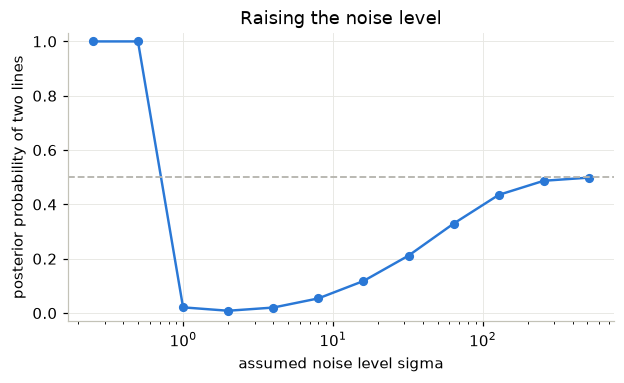

In [13]:
sigmas = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0, 512.0]
p_post = [p_two_lines(xs2, ys2, sigma=s) for s in sigmas]
for s, p in zip(sigmas, p_post):
    print(f"sigma = {s:5}   P(two lines | data) = {p:.6f}")

fig, ax = plt.subplots()
ax.plot(sigmas, p_post, "o-", color=BLUE, lw=1.6, ms=5)
ax.axhline(0.5, color=MUTED, lw=1.2, ls="--")
ax.set(xscale="log", ylim=(-0.03, 1.03), xlabel="assumed noise level sigma",
       ylabel="posterior probability of two lines", title="Raising the noise level");

At the true noise level the two-line model wins outright.

However, if we raise the noise to $\sigma = 1$, the *one*-line model is already
preferred, and around $\sigma = 2$ the two-line model has less than one chance in a
hundred. This is the ambiguity we noted earlier: with that much noise, the scatter
around a single line is "explained" by the noise, and the two-line model is penalized
for its flexibility. It spreads its prior predictions over every assignment and two
lines' worth of coefficients, so each particular data set gets a smaller share of them.

This is known as the Bayesian Occam's razor: when both models fit the data well, the
simpler one is preferred. Only when the noise is so large that neither model explains
anything, here hundreds of times the spread of the data, do the two models become
equally good, and the posterior returns to the prior of one half.

## Non-Linear Features

Often data are not linear, but a polynomial regression can still capture them. One
challenge is that we rarely know in advance what degree of polynomial we need. The
Bayesian approach is to leave the choice to the model: put a prior on the degree and
let the data decide.

The Bayesian Occam's razor applies here as well. A higher-degree polynomial has more
parameters, so if a lower-degree one fits the data well it is strongly preferred. This
is in contrast to the usual trouble with polynomial regression: a fixed high degree
gives the model lots of flexibility and it overfits, and a single point estimate such
as the maximum likelihood fit always favors the higher degree, which fits the data
better but extrapolates poorly.

In the program, a polynomial is its list of coefficients, lowest degree first. The
constant term is always there, and after each term a coin decides whether to stop, so
the degree has a truncated geometric prior. `evaluate` uses Horner's rule, which needs
only additions and multiplications by constants, so the model stays linear-Gaussian
whatever the degree, and the query returns the degree together with the coefficients.
Inside the model, $x$ is divided by 10, so that the features $x, x^2, \ldots$ all lie in
$[0, 1]$ and one wide prior, $N(0, 50)$, suits the coefficients of every degree. Keep
features on a sensible scale: with $x$ up to 10, $x^4$ reaches $10^4$, and the
covariance matrices become numerically singular.

We generate some data from a parabola.

degree 0: 0.0000   degree 1: 0.0000   degree 2: 0.7109   degree 3: 0.2081   degree 4: 0.0810


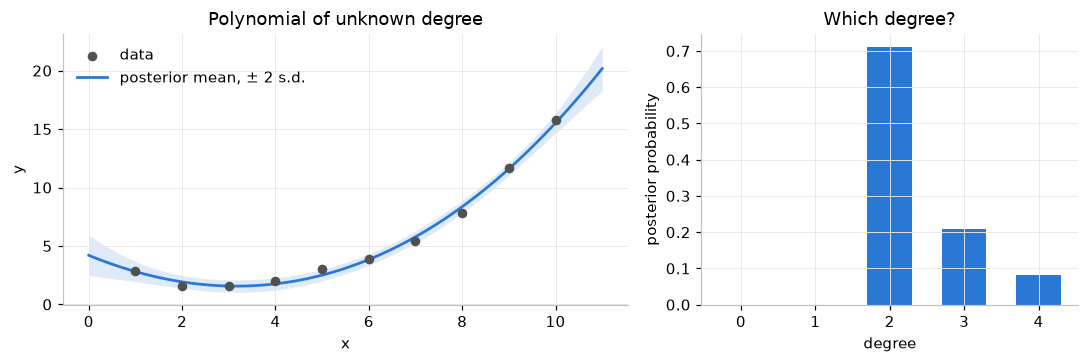

In [14]:
rng = np.random.default_rng(5)
ys_quad = 5.0 - 2.0 * xs + 0.3 * xs ** 2 + rng.normal(0, SIGMA, size=xs.size)

def poly_program(xs, ys, sigma=SIGMA, max_degree=4, p_stop=0.5, coeff_sd=50.0):
    return f"""
(define xs {pluck_list(xs)})
(define ys {pluck_list(ys)})

;; A polynomial as its list of coefficients, lowest degree first. The constant
;; term is always there; after each term a coin decides whether to stop.
(define (random-poly remaining)
  (Cons (normal 0.0 {num(coeff_sd)})
        (if (or (== remaining 0) (flip {num(p_stop)}))
            Nil
            (random-poly (dec remaining)))))

;; Horner's rule: c0 + x*(c1 + x*(c2 + ...)).
(define (evaluate cs x)
  (match cs
    Nil => 0.0
    Cons c cs => (+. c (*. x (evaluate cs x)))))

;; x is scaled to [0, 1] before it is fed to the polynomial.
(define (observe cs xs ys)
  (list=? real=? (map (fn x -> (normal (evaluate cs (/. x 10.0)) {num(sigma)})) xs) ys))

(define-type poly (Poly degree cs))
(query poly
  (let ((cs (random-poly {max_degree})))
    (Posterior (Poly (dec (length cs)) cs) (observe cs xs ys))))
"""

def degree_of(value):
    return int(re.match(r"\(Poly (\d+)", value).group(1))

def plot_poly_fit(post, xs, ys, title):
    p_degree = marginal(post, key=degree_of)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [3, 2]})
    plot_points(ax1, xs, ys)
    plot_band(ax1, grid, *curve_band(post, grid / 10.0), label=r"posterior mean, $\pm$ 2 s.d.")
    ax1.set(xlabel="x", ylabel="y", title=title)
    ax1.legend()
    degrees = range(0, 5)
    ax2.bar(degrees, [p_degree.get(d, 0.0) for d in degrees], color=BLUE, width=0.6)
    ax2.set(xlabel="degree", ylabel="posterior probability", title="Which degree?")
    fig.tight_layout()
    return p_degree

post_quad = run_pluck(poly_program(xs, ys_quad))["poly"]
p_degree = plot_poly_fit(post_quad, xs, ys_quad, "Polynomial of unknown degree")
print("   ".join(f"degree {d}: {p:.4f}" for d, p in sorted(p_degree.items())))

The posterior favors degree 2 but keeps some mass on 3 and 4. The higher degrees can
fit the data just as well, but Occam's razor and the prior, which halves with every
extra term, favor the lower degrees. The curve is the mixture over all the degrees,
weighted by their probabilities.

> **How does changing back to the earlier linear data change the posterior on the
> degree?**

degree 0: 0.0000   degree 1: 0.9736   degree 2: 0.0237   degree 3: 0.0020   degree 4: 0.0007


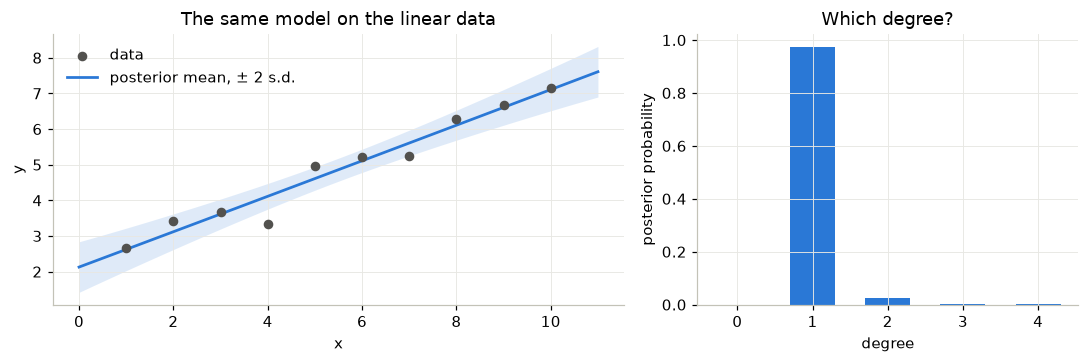

In [15]:
post_lin = run_pluck(poly_program(xs, ys))["poly"]
p_degree_lin = plot_poly_fit(post_lin, xs, ys, "The same model on the linear data")
print("   ".join(f"degree {d}: {p:.4f}" for d, p in sorted(p_degree_lin.items())))

As expected, the posterior puts almost all of its mass on degree 1.

> **How would you change this model to also allow for multiple lines to be generated,
> or to incorporate outliers?**

Combine it with the previous sections. For two curves, draw two polynomials and flip a
coin for each point to decide which one it is read from, as `observe-two` did, with
`evaluate` in place of `predict`. For outliers, give each point an indicator that
switches its noise level, as in the robust model. Both multiply the number of discrete
worlds, but inference stays exact, and fast for a dozen points.

## More things to try

- **Multiple covariates.** Give each point a list of features and take a dot product
  with a list of Gaussian coefficients: a recursive `dot` that adds `(*. w x)` terms is
  an affine combination, so it stays exact. `examples/spike_and_slab.pluck` does this on
  the four-covariate Hald cement data, with a `flip` per coefficient that decides
  whether the covariate is in the model at all (a spike-and-slab prior), and
  `examples/mv_dot_regression.pluck` uses Pluck's vectors and `dot` instead of a list.
- **Piecewise regression.** Draw a changepoint index with `uniform` over the
  positions, and read the points before it from one line and the points after it from
  another: a mixture of two lines where the assignment is decided by position instead
  of by a coin. To make the function continuous, observe that the two lines agree at
  the changepoint: `(real=? (-. (predict l1 x-cp) (predict l2 x-cp)) 0.0)` is an affine
  observation, so it is exact too. `examples/fig_changepoint_listing.pluck` goes
  further and makes the number of changepoints unknown.
- **Learn the noise level.** Hybrid Pluck cannot put a continuous prior on `sigma`
  (LANGUAGE.md, Section 6), but it can choose it from a few candidates with
  `discrete`: `(discrete (0.1 1) (1.0 1) (10.0 1))` picks a standard deviation of 0.1,
  1 or 10 with equal probability, and the posterior over that choice is exact.